In [1]:
import pennylane as qml
from pennylane import math as qml_math
from pennylane import numpy as np
from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit.visualization import array_to_latex
from typing import Callable
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from functools import reduce
from scipy.stats import wasserstein_distance
from tqdm import tqdm

In [2]:
rng = np.random.default_rng(42)

In [3]:
dev = qml.device("default.qubit")
# dev = qml.device("default.mixed")
### Requires adjusting the error threshold in the following file to allow for probabilities that are close to 1, caused by non-unitary operations:
### ~/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/devices/qubit/sampling.py:530
# dev = qml.device("default.qubit", shots=10000)
# dev = qml.device("default.qubit", shots=1000) # No seed, measurement results will be the same between runs.
# dev = qml.device("default.qubit", shots=1000, seed=rng) # Seed will cause measurements results to be stochastic.
# dev = qml.device("default.qubit", shots=100)
# dev = qml.device("default.qubit", shots=10)
# dev = qml.device("default.qubit", shots=None)

In [4]:
from pennylane.devices import DefaultQubit

In [5]:
def is_unitary(m: np.ndarray):
    return np.allclose(np.eye(m.shape[0]), m * m.T.conj())

def is_hermitian(m: np.ndarray):
    return np.allclose(m, m.T.conj())

def is_sorted(x: np.ndarray):
    x = np.array(x)
    return bool(np.all(x[:-1] <= x[1:]))

def softmax(x: np.ndarray, axis=None):
    y = np.exp(x - np.max(x, axis=axis, keepdims=True)) # Stabilize to prevent overflow.
    return y / np.sum(y, axis=axis, keepdims=True)

In [6]:
from typing import Any

@qml.qnode(dev)
def circuit(
    wires: list[int],
    funcs: list[Callable[[list[int]], None]] = [],
    func_measure: Callable[[list[int]], Any] = None,
    ):
    if not funcs:
        funcs = [lambda wires: None]
    for func in funcs:
        func(wires)
    if func_measure is not None:
        return func_measure(wires)
    else:
        return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires)

In [7]:
def prepare_actions(
    wires_actions: list[int],
    action_probs_vec: np.ndarray, # shape (n_actions,),
    normalize: bool = False,
    ):
    n_actions = action_probs_vec.shape[0]
    
    d_actions = int(np.log2(n_actions))
    # print(f"{d_actions=}")
    if n_actions != 2**d_actions:
        raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(np.sqrt(action_probs_vec), wires=wires_actions, normalize=normalize) # Must normalize since inputs are probability vectors.


def prepare_returns(
    wires_actions: list[int],
    wires_returns: list[int],
    returns_probs_matrix: np.ndarray, # shape (n_actions, n_returns)
    normalize: bool = False,
    ):
    n_actions, n_returns = returns_probs_matrix.shape
    
    d_returns = int(np.log2(n_returns))
    # print(f"{d_returns=}")
    if n_returns != 2**d_returns:
        raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(np.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=normalize) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_actions)


def prepare_action_returns(
    wires: list[int], 
    action_probs_vec: np.ndarray, # shape (n_actions,),
    returns_probs_matrix: np.ndarray, # shape (n_actions, n_returns)
    normalize: bool = False,
    ):
    # print(f"{action_probs_vec.shape=}")
    # print(f"{returns_probs_matrix.shape=}")
    n_actions = action_probs_vec.shape[0]
    n_returns = returns_probs_matrix.shape[1]
    
    # Get number of qubits needed for actions and returns.
    # (for now) The number of actions and returns must be powers of 2 for this to work properly.
    d_actions = int(np.log2(n_actions))
    # print(f"{d_actions=}")
    if n_actions != 2**d_actions:
        raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    d_returns = int(np.log2(n_returns))
    # print(f"{d_returns=}")
    if n_returns != 2**d_returns:
        raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Partition wires into action and return wires.
    # Wire order is: [action wires, return wires]
    if len(wires) != d_actions + d_returns:
        raise ValueError(f"wires must have length {d_actions + d_returns}, got {len(wires)}.")
    wires_action = wires[:d_actions]
    wires_returns = wires[d_actions:]
    # print(f"{wires_action=}, {wires_returns=}")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(np.sqrt(action_probs_vec), wires=wires_action, normalize=normalize) # Must normalize since inputs are probability vectors.
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(np.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=normalize) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_action)

In [8]:
n_actions = 64 # 4, 8, 16, 32, 64
n_returns = 4 # 4, 8, 16, 32, 64
d_actions = int(np.log2(n_actions))
d_returns = int(np.log2(n_returns))

In [9]:
returns_probs_matrix = np.abs(rng.normal(0, 1, size=(n_actions, n_returns)))
returns_probs_matrix = returns_probs_matrix / np.sum(returns_probs_matrix, axis=1, keepdims=True)  # Normalize to make it a probability vector (sums to 1).

# returns_probs_matrix[[0,3]] = returns_probs_matrix[[3,0]] # Swap some rows.
# returns_probs_matrix[[1,3]] = returns_probs_matrix[[1,3]] # Swap some rows.

In [10]:
# #### FORCE zn-1 to be very small probability.
# # returns_probs_matrix[:,-1] = 1e-2
# returns_probs_matrix[:,-1] = returns_probs_matrix[:,-1]*1e-2
# returns_probs_matrix = returns_probs_matrix / np.sum(returns_probs_matrix, axis=1, keepdims=True)
# # returns_probs_matrix = softmax(returns_probs_matrix, axis=1)

In [11]:
returns_probs_matrix

tensor([[0.1003773 , 0.34258268, 0.24720722, 0.3098328 ],
        [0.52769221, 0.35219764, 0.03457671, 0.08553344],
        [0.00664857, 0.33756712, 0.34799596, 0.30778835],
        [0.02620189, 0.44730486, 0.18551415, 0.3409791 ],
        [0.16345267, 0.42503481, 0.38938234, 0.02213019],
        [0.0824225 , 0.3035984 , 0.54508077, 0.06889832],
        [0.25522827, 0.20982629, 0.31718779, 0.21775765],
        [0.12169201, 0.12702528, 0.6314534 , 0.11982931],
        [0.16680176, 0.26498907, 0.20058157, 0.3676276 ],
        [0.04690783, 0.34586041, 0.3394075 , 0.26782426],
        [0.34030546, 0.24868796, 0.30470947, 0.1062971 ],
        [0.08157572, 0.15288646, 0.60922088, 0.15631694],
        [0.40729105, 0.04054176, 0.17344733, 0.37871986],
        [0.50489143, 0.11076321, 0.16297991, 0.22136545],
        [0.07633949, 0.41477837, 0.24022884, 0.2686533 ],
        [0.60825222, 0.12104   , 0.05882506, 0.21188272],
        [0.30713898, 0.34260229, 0.15059485, 0.19966388],
        [0.248

In [12]:
returns_probs_matrix.sum(axis=1)

tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.], requires_grad=True)

In [13]:
# returns_atoms_values_original = np.array([float(i)+1 for i in range(n_returns)])/n_returns*4 # More steep than previous.
returns_atoms_values_original = np.array([-1,0,1,100])
# returns_atoms_values_original = np.array([-10,-2,-1,0,1,2,5,100])
# returns_atoms_values_original = np.array([-1,0,1,10])
# returns_atoms_values_original = np.array([-1,0,100,1])
# returns_atoms_values_original_normalized = softmax(returns_atoms_values_original) # Turn into probability distribution.
returns_atoms_values_original_normalized = (returns_atoms_values_original + np.abs(returns_atoms_values_original.min()) + 1e-2) / (returns_atoms_values_original + np.abs(returns_atoms_values_original.min()) + 1e-2).sum() # Turn into probability distribution.
returns_atoms_values = returns_atoms_values_original_normalized.copy()
#######
# returns_atoms_values_original = softmax(np.array([1.]*n_returns)) # Equal superposition.
# returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/n_returns/16) # Monotonically increasing, but very shallow.
# returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/n_returns) # Monotonically increasing, but similar values.
# returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/2.) # Slightly steeper than previous.
# returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/n_returns*4) # More steep than previous.
# returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/n_returns*8) # Even more steep than previous.
########
# returns_atoms_values_original = returns_atoms_values_original[::-1] # Monotonically decreasing
########
# returns_atoms_values_original = returns_atoms_values_original * (n_returns / n_actions)
#########
# np.random.shuffle(returns_atoms_values_original) # Shuffle the return atoms, so that they are not monotonically increasing or decreasing.
#########
# returns_atoms_values = returns_atoms_values_original.copy() 
# returns_atoms_values = returns_atoms_values * (n_returns / n_actions)

# returns_atoms_values = returns_atoms_values_original.copy() # DOES NOT WORK. Must at least have square-root term.
# returns_atoms_values = np.sqrt(returns_atoms_values) # This is minimal working representation. Must at least have square-root of probability distribution. Causes L2-norm of diagonal unitary to be 1.
returns_atoms_values = np.sqrt(returns_atoms_values * n_returns) # values - epsilon (epsilon is zero).
# returns_atoms_values = np.sqrt(returns_atoms_values * n_actions) # values - epsilon (epsilon is zero).
# returns_atoms_values = np.sqrt(returns_atoms_values * n_actions) - 0.0196 # values - epsilon.
# returns_atoms_values = np.sqrt(returns_atoms_values * n_actions) - 0.1 # values - epsilon.
# returns_atoms_values = np.sqrt(returns_atoms_values * n_actions) - 0.001 # values - epsilon.
# returns_atoms_values = np.sqrt(returns_atoms_values*n_actions) # causes a 1:1 match with computing weighted action distribution via expected return.
# returns_atoms_values = np.sqrt(returns_atoms_values*(n_actions*n_returns)/(d_actions*d_returns)*2)
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions # causes L2-norm of circuit probs to be close to 1.
# returns_atoms_values = np.sqrt(returns_atoms_values*n_returns/n_actions)
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions/n_returns
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_returns/n_actions
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions/n_returns
# returns_atoms_values = 1j*np.sqrt(returns_atoms_values)*n_returns/n_actions
# returns_atoms_values = 1j*np.sqrt(returns_atoms_values)
# returns_atoms_values = returns_atoms_values + 1j*np.sqrt(1 - returns_atoms_values**2.) # Convert to complex such that the norm of each element is 1. This will cause the diagonal matrix to be unitary.
# returns_atoms_values = np.sqrt(1 - returns_atoms_values**2.) + 1j*returns_atoms_values # Convert to complex such that the norm of each element is 1. This will cause the diagonal matrix to be unitary.
# returns_atoms_values = np.exp(2*np.pi*1j*returns_atoms_values)
# returns_atoms_values = returns_atoms_values / np.linalg.norm(returns_atoms_values)
# returns_atoms_values = np.exp(1j*returns_atoms_values)

##################
# returns_atoms_values = returns_atoms_values/n_actions
##################

# # Swap real/imaginary parts.
# r = returns_atoms_values.real.copy()
# i = returns_atoms_values.imag.copy()
# returns_atoms_values.real = i
# returns_atoms_values.imag = r

U_returns_atoms = np.diag(returns_atoms_values)
##########
# U_returns_atoms = (U_returns_atoms/np.linalg.norm(U_returns_atoms)) * 1/np.sqrt(n_returns)*n_returns

In [14]:
returns_atoms_values_original

tensor([ -1,   0,   1, 100], requires_grad=True)

In [15]:
returns_atoms_values_original_normalized

tensor([9.61168781e-05, 9.70780469e-03, 1.93194925e-02, 9.70876586e-01], requires_grad=True)

In [16]:
U_returns_atoms

tensor([[0.01960784, 0.        , 0.        , 0.        ],
        [0.        , 0.19705638, 0.        , 0.        ],
        [0.        , 0.        , 0.27798915, 0.        ],
        [0.        , 0.        , 0.        , 1.9706614 ]], requires_grad=True)

In [17]:
action_probs_vec_original = [1./n_actions] * n_actions  # Uniform distribution for simplicity
action_probs_vec_original = np.array(action_probs_vec_original) # Convert to numpy array for vectorization.
action_probs_vec = action_probs_vec_original.copy() # Preserve the original.

In [18]:
probs_actions_carryover = None # Reset circuit carryover probabilities between runs.

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_91093/3480102381.py:21: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


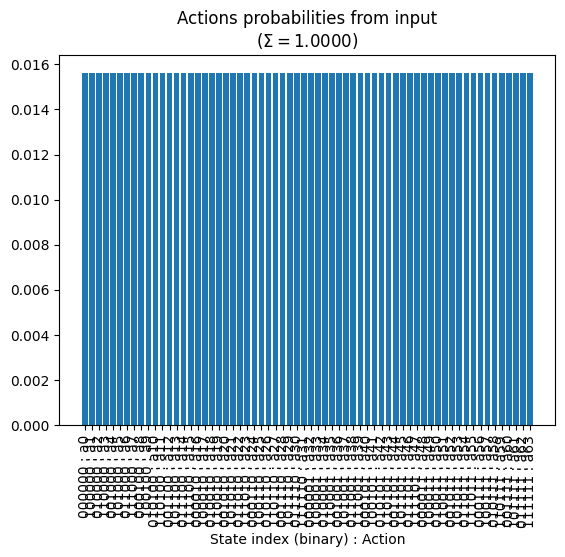

<Figure size 640x480 with 0 Axes>

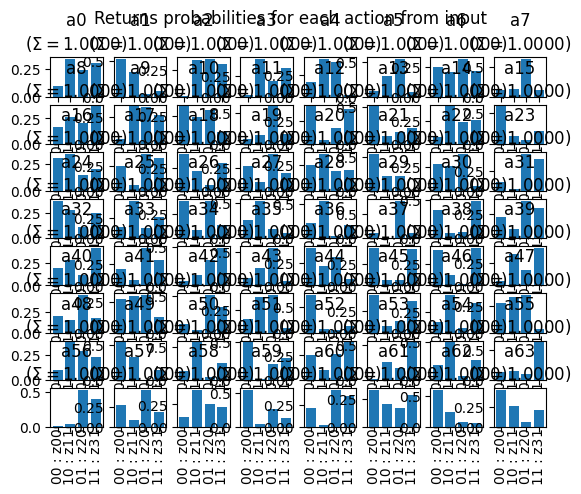

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_91093/3480102381.py:68: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


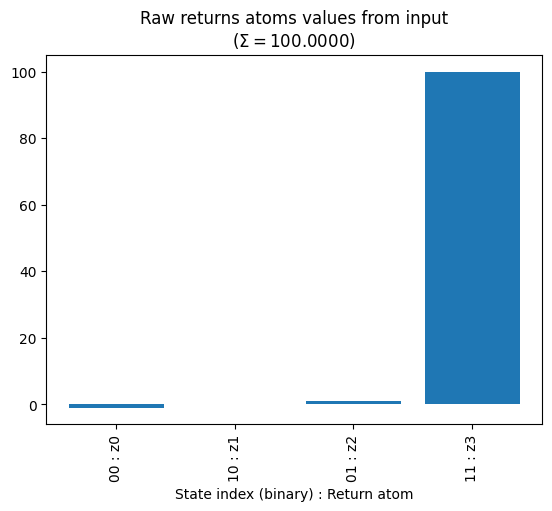

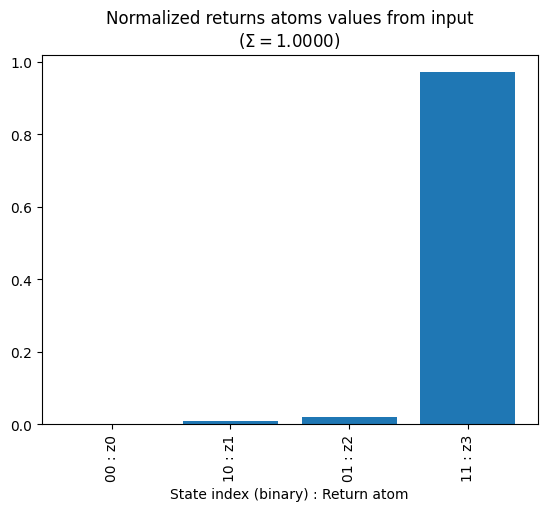

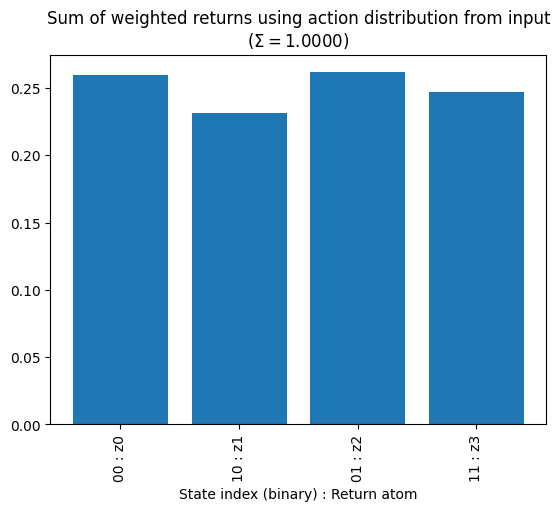

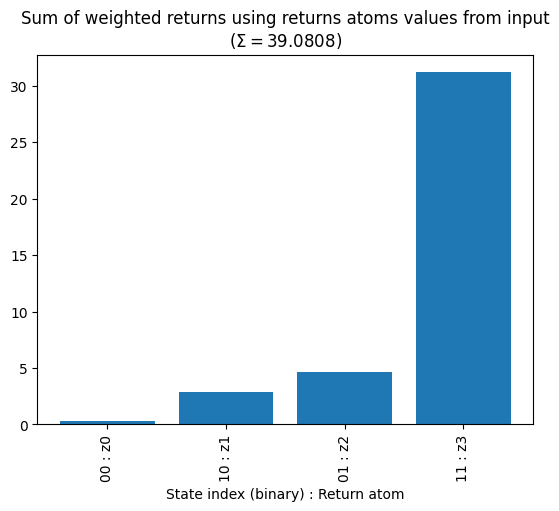

<Figure size 640x480 with 0 Axes>

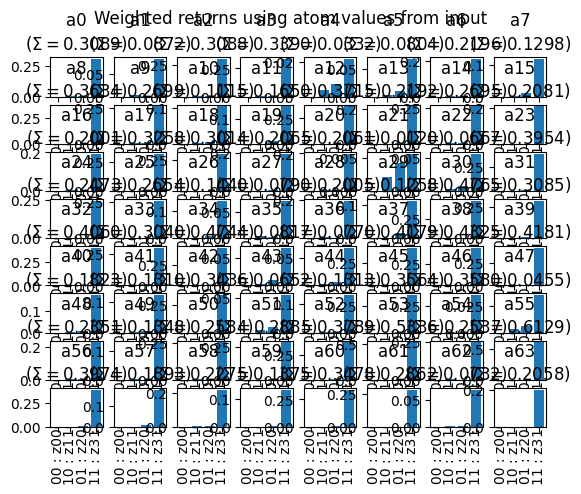

Compounded: [8.51085052e-03 1.52344702e-05 8.49771508e-03 1.35391833e-02
 1.21107093e-07 1.01487936e-05 1.54507983e-03 1.11387894e-04
 1.91677377e-02 4.33613314e-03 5.22151122e-05 3.70257669e-04
 2.13983012e-02 1.53056461e-03 4.30096390e-03 1.18007574e-03
 9.70786018e-04 1.11126443e-02 7.52607973e-03 1.13540581e-03
 1.12549660e-03 7.62164512e-10 4.00312044e-06 2.92491924e-02
 2.80007021e-03 3.98599914e-03 1.87169970e-04 9.32852919e-06
 9.79021966e-04 9.51849110e-05 7.43360238e-02 8.45549086e-03
 3.33775071e-02 7.85940145e-03 7.26649547e-02 1.10094521e-05
 8.20840497e-06 3.85541820e-02 4.57584463e-02 3.86658041e-02
 6.08395009e-04 1.16696485e-04 1.44975465e-02 3.56812704e-06
 1.18156035e-04 1.73855566e-02 1.77923813e-02 5.87114104e-07
 2.17260639e-03 1.34804249e-04 3.48247079e-03 6.04216840e-03
 2.36108246e-02 1.30844456e-01 3.18207186e-03 2.61531871e-01
 2.99898960e-02 7.34599646e-04 1.84491393e-03 1.48447605e-04
 1.53922999e-02 5.80612424e-03 6.35832332e-06 1.11581818e-03]


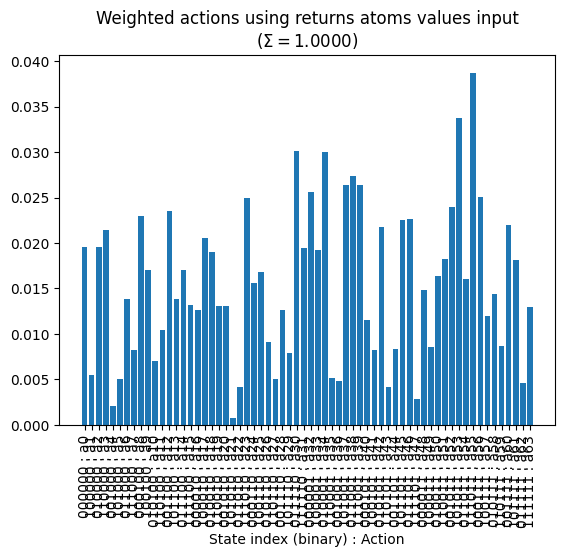

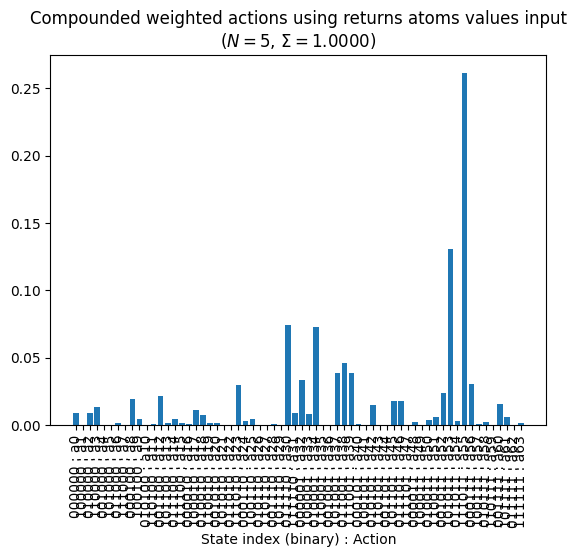

In [19]:
### Plot all inputs for visualization.

plt.figure()
plt.bar(np.arange(n_actions), action_probs_vec)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Actions probabilities from input\n($\\Sigma = {action_probs_vec.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")


plt.figure()
d = int(np.ceil(np.sqrt(n_actions)))
fig, axs = plt.subplots(d, d)
axs = axs.flatten()
for a in range(n_actions):
    y = returns_probs_matrix[a]
    axs[a].bar(np.arange(n_returns), y)
    axs[a].set_xticks(np.arange(n_returns))
    axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
    axs[a].set_title(f"a{a}\n($\\Sigma = {y.sum():.4f}$)")
plt.suptitle("Returns probabilities for each action from input")
plt.tight_layout()
plt.show()


plt.figure()
plt.bar(np.arange(n_returns), returns_atoms_values_original)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Raw returns atoms values from input\n($\\Sigma = {returns_atoms_values_original.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")

plt.figure()
plt.bar(np.arange(n_returns), returns_atoms_values_original_normalized)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Normalized returns atoms values from input\n($\\Sigma = {returns_atoms_values_original_normalized.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")

#########

plt.figure()
df = pd.DataFrame(returns_probs_matrix, columns=[f"z{i}" for i in range(n_returns)], index=[f"a{i}" for i in range(n_actions)])
weights = pd.Series(action_probs_vec, index=[f"a{i}" for i in range(n_actions)])
y = (df.T * weights).sum(axis=1).to_numpy()
plt.bar(np.arange(n_returns), y)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Sum of weighted returns using action distribution from input\n($\\Sigma = {y.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")


plt.figure()
M = np.einsum('jj,ij->j', U_returns_atoms, returns_probs_matrix)
y = np.abs(M)
plt.bar(np.arange(n_returns), y)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Sum of weighted returns using returns atoms values from input\n($\\Sigma = {y.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")

plt.figure()
d = int(np.ceil(np.sqrt(n_actions)))
fig, axs = plt.subplots(d, d)
axs = axs.flatten()
for a in range(n_actions):
    y = returns_probs_matrix[a] * returns_atoms_values_original_normalized
    axs[a].bar(np.arange(n_returns), y)
    axs[a].set_xticks(np.arange(n_returns))
    axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
    axs[a].set_title(f"a{a}\n($\\Sigma = {y.sum():.4f}$)")
plt.suptitle("Weighted returns using atom values from input")
plt.tight_layout()
plt.show()

#########

plt.figure()
y = (returns_probs_matrix @ returns_atoms_values_original_normalized) # Perform expected value once.
y /= y.sum() # Normalize.
plt.bar(np.arange(n_actions), y)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Weighted actions using returns atoms values input\n($\\Sigma = {y.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")

plt.figure()
# N = n_returns
N = 5
y = (returns_probs_matrix @ returns_atoms_values_original_normalized)**N # Perform expected value, then compound result multiple times
y /= y.sum() # Normalize.
plt.bar(np.arange(n_actions), y)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Compounded weighted actions using returns atoms values input\n($N={N}$, $\\Sigma = {y.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")
print(f"Compounded: {y}")

In [20]:
### Re-run the circuit from here down if you want to re-use the action probabilities from the previous run.
### Otherwise, run from the line above.

probs_actions_carryover = globals().get('probs_actions_carryover', None)
if probs_actions_carryover is not None:
    action_probs_vec = probs_actions_carryover
    print(f'Using action probabilities from previous run: {action_probs_vec}')

In [21]:
# wires = list(range(d_actions + d_returns))
# wires_actions = wires[:d_actions]
# wires_returns = wires[d_actions:]

# # def domeasure():
# #     m = [qml.measure(w) for w in wires_actions]
# #     print(m)

# funcs = [
#     lambda wires: prepare_action_returns(wires, action_probs_vec, returns_probs_matrix, normalize=True), # Prepare the action and return distributions.
#     lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
#     ###########
#     # lambda wires: domeasure(),
#     # lambda wires: qml.measure(wires_actions[0]),
#     # lambda wires: qml.measure(wires_actions[1]),
#     ###########
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
# ]
# func_measure = lambda wires: (
#     # qml.state(),
#     # qml.probs(wires=wires),
#     # qml.density_matrix(wires),
#     qml.probs(wires=wires_actions),
#     qml.probs(wires=wires_returns),
#     )
# (
#     # state,
#     # probs,
#     # rho,
#     probs_actions,
#     probs_returns,
#     ) = circuit(wires, funcs=funcs, func_measure=func_measure)

# # # replace state and density matrix rho with dummy values.
# # state = np.array(list(range(2**len(wires))))
# # state = state / np.linalg.norm(state)
# # rho = np.identity(len(state))

# # print(f"{wires_actions=}")
# # print(f"{wires_returns=}")
# # print(f"{probs_actions=}")
# # print(f"{probs_returns=}")
# # print(f"{probs=}")


# # # Split the system density matrix into density matrices for the actions and returns subsystems.
# # rho_actions = qml_math.partial_trace(rho, indices=wires_returns) # This is the reduced density matrix for actions, trace out the returns.
# # rho_returns = qml_math.partial_trace(rho, indices=wires_actions) # This is the reduced density matrix for returns, trace out the actions.

# # display(array_to_latex(action_probs_vec, prefix="\\textrm{Action probabilities vector:~~}"))
# # display(array_to_latex(returns_probs_matrix, prefix="\\textrm{Returns probabilities matrix:~~}"))
# # display(array_to_latex(returns_atoms_values, prefix="\\textrm{Returns atoms values:~~}"))
# # display(array_to_latex(returns_probs_matrix @ returns_atoms_values_original, prefix="\\textrm{Action expected returns (return dist @ return values):~~}"))
# #######
# # display(array_to_latex(state, prefix="\\textrm{State:~~}"))
# # display(Statevector(state).draw(output='latex', prefix="\\textrm{State:~~}"))
# # display(array_to_latex(probs, prefix="\\textrm{Probabilities:~~}"))
# # display(DensityMatrix(rho).draw(output='latex', prefix="\\textrm{Rho:~~}"))
# # display(array_to_latex(rho_actions, prefix="\\textrm{Rho actions:~~}"))
# # display(DensityMatrix(rho_actions).draw(output='latex', prefix="\\textrm{Rho actions:~~}"))
# # display(array_to_latex(rho_returns, prefix="\\textrm{Rho returns:~~}"))
# # display(DensityMatrix(rho_returns).draw(output='latex', prefix="\\textrm{Rho returns:~~}"))

In [22]:
# # U_returns_atoms = np.diag(np.sqrt(returns_atoms_values_original * (n_actions/n_returns)))
# # # np.diag(np.sqrt(returns_atoms_values_original * (n_actions/n_returns)))

# U_returns_atoms = softmax(np.array([float(i)+1 for i in range(n_returns)])/n_returns)
# # U_returns_atoms = softmax(np.array([float(i)+1 for i in range(n_returns)])/n_returns)[::-1]
# U_returns_atoms = np.diag(np.sqrt(U_returns_atoms))
# U_returns_atoms

In [23]:
# (softmax(np.array([float(i)+1 for i in range(n_returns)])/n_returns) * n_returns).sum()

In [24]:
# ### This does not work :(

# U_reset = np.zeros((2**d_returns, 2**d_returns))
# U_reset[0] = np.ones((1, 2**d_returns)) # Fill top row with ones.
# U_reset[0] = U_reset[0]/U_reset[0].sum() # Fill top row with ones.
# U_reset

In [25]:
# from pennylane.measurements import MidMeasureMP

In [26]:
################## Prepare, compute, measure, re-upload, ...
wires = list(range(d_actions + d_returns))
wires_actions = wires[:d_actions]
wires_returns = wires[d_actions:]

print(f"{action_probs_vec=}")
print(f"{returns_probs_matrix=}")
print(f"{U_returns_atoms=}")

funcs = [
    lambda wires: prepare_actions(wires_actions=wires_actions, action_probs_vec=action_probs_vec, normalize=True),
    lambda wires: prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True),
    lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False), # We know it's not unitary, so don't check.
    lambda wires: [qml.measure(wires=w, reset=True) for w in wires_returns],
    ########
    # lambda wires, k=0: [qml.measure(wires=w, reset=True, postselect=int(f"{k:0{d_returns}b}"[::-1][j])) for j, w in enumerate(wires_returns)],
    ########
    # lambda wires: [qml.measure(wires=w, reset=True, postselect=0) for w in wires_returns],
    # lambda wires: qml.WireCut(wires=wires_returns),
    # lambda wires: qml.QubitUnitary(U_reset, wires=wires_returns, unitary_check=False),
    # lambda wires: [qml.ResetError(p0=1, p1=0, wires=w) for w in wires_returns],
    # lambda wires: [MidMeasureMP(wires=w, reset=True, postselect=None) for w in wires_returns],
]
# N = 0
# N = 2
# N = 5
N = n_returns
# N = int(n_returns/2)
# N = n_returns*2
# N = n_returns+1
# N = n_returns**2
# N = int(np.sqrt(n_actions * n_returns)) # Run multiple times.
# N = n_actions * n_returns
# N = 2*N
# N = 2*N
# N = 2*N
print(f"Re-uploading {N} times")
for i in range(N):
    funcs.extend([
        # lambda wires: [qml.measure(wires=w, reset=True) for w in wires_returns],
        lambda wires: prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True),
        lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False), # We know it's not unitary, so don't check.
        lambda wires: [qml.measure(wires=w, reset=True) for w in wires_returns],
        ########
        # lambda wires, k=i+1: [qml.measure(wires=w, reset=True, postselect=int(f"{k:0{d_returns}b}"[::-1][j])) for j, w in enumerate(wires_returns)],
        ########
        # lambda wires: [qml.measure(wires=w, reset=True, postselect=0) for w in wires_returns],
        # lambda wires: qml.WireCut(wires=wires_returns),
        # lambda wires: qml.QubitUnitary(U_reset, wires=wires_returns, unitary_check=False),
        # lambda wires: [qml.ResetError(p0=1, p1=0, wires=w) for w in wires_returns],
        # lambda wires: [MidMeasureMP(wires=w, reset=True, postselect=None) for w in wires_returns],
    ])


###################
# funcs.extend([
#     lambda wires: qml.measure(wires=wires_returns[0], reset=True, postselect=None), # postselect=0
#     lambda wires: qml.measure(wires=wires_returns[1], reset=True, postselect=None), # postselect=0
#     lambda wires: prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True),
#     lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     ########
#     lambda wires: qml.measure(wires=wires_returns[0], reset=True, postselect=None), # postselect=0
#     lambda wires: qml.measure(wires=wires_returns[1], reset=True, postselect=None), # postselect=1
#     lambda wires: prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True),
#     lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     ########
#     lambda wires: qml.measure(wires=wires_returns[0], reset=True, postselect=None), # postselect=1
#     lambda wires: qml.measure(wires=wires_returns[1], reset=True, postselect=None), # postselect=0
#     lambda wires: prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True),
#     lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     ########
#     lambda wires: qml.measure(wires=wires_returns[0], reset=True, postselect=None), # postselect=1
#     lambda wires: qml.measure(wires=wires_returns[1], reset=True, postselect=None), # postselect=1
#     lambda wires: prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True),
#     lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
# ])
###################

# # Measure once at the end.
# if N is not None and N > 0:
#     funcs.extend([
#         lambda wires: [qml.measure(wires=w, reset=True) for w in wires_returns],
#     ])

func_measure = lambda wires: (
    qml.probs(wires=wires_actions),
    qml.probs(wires=wires_returns),
    )
(probs_actions, probs_returns) = circuit(wires, funcs=funcs, func_measure=func_measure)
##################

action_probs_vec=tensor([0.015625, 0.015625, 0.015625, 0.015625, 0.015625, 0.015625,
        0.015625, 0.015625, 0.015625, 0.015625, 0.015625, 0.015625,
        0.015625, 0.015625, 0.015625, 0.015625, 0.015625, 0.015625,
        0.015625, 0.015625, 0.015625, 0.015625, 0.015625, 0.015625,
        0.015625, 0.015625, 0.015625, 0.015625, 0.015625, 0.015625,
        0.015625, 0.015625, 0.015625, 0.015625, 0.015625, 0.015625,
        0.015625, 0.015625, 0.015625, 0.015625, 0.015625, 0.015625,
        0.015625, 0.015625, 0.015625, 0.015625, 0.015625, 0.015625,
        0.015625, 0.015625, 0.015625, 0.015625, 0.015625, 0.015625,
        0.015625, 0.015625, 0.015625, 0.015625, 0.015625, 0.015625,
        0.015625, 0.015625, 0.015625, 0.015625], requires_grad=True)
returns_probs_matrix=tensor([[0.1003773 , 0.34258268, 0.24720722, 0.3098328 ],
        [0.52769221, 0.35219764, 0.03457671, 0.08553344],
        [0.00664857, 0.33756712, 0.34799596, 0.30778835],
        [0.02620189, 0.44730486, 0.1855

In [27]:
# circuit.device.tracker.latest

In [28]:
# def shots_info(totals, history, latest):
#     print(f"{totals=}")
#     print(f"{history=}")
#     print(f"{latest=}")
#     # if 'shots' in latest:
#     #     print(f"Total shots: {totals['shots']}")
# with qml.Tracker(circuit.device, callback=shots_info) as tracker:
#     (probs_actions, probs_returns) = circuit(wires, funcs=funcs, func_measure=func_measure)

In [29]:
# #### Cascade of quantum circuits.

# wires = list(range(d_actions + d_returns))
# wires_actions = wires[:d_actions]
# wires_returns = wires[d_actions:]

# N = 1 # Run once.
# # N = int(np.sqrt(n_actions * n_returns)) # Run multiple times.
# print(f"Running {N} times")

# for _ in range(N):
#     funcs = [
#         lambda wires: prepare_action_returns(wires, action_probs_vec, returns_probs_matrix, normalize=True), # Prepare the action and return distributions.
#         lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False), # We know it's not unitary, so don't check.
#     ]
#     func_measure = lambda wires: (
#         qml.probs(wires=wires_actions),
#         qml.probs(wires=wires_returns),
#         )
#     (probs_actions, probs_returns) = circuit(wires, funcs=funcs, func_measure=func_measure)
#     if N > 1:
#         action_probs_vec = probs_actions.copy()

In [30]:
# probs_actions = probs_actions/sum(probs_actions) # Re-normalize action probabilities.

In [31]:
probs_actions # Action probabilities before normalization.

tensor([4.50147691e-02, 8.05766894e-05, 4.49452945e-02, 7.16101417e-02,
        6.40547946e-07, 5.36780195e-05, 8.17208712e-03, 5.89142097e-04,
        1.01380148e-01, 2.29342569e-02, 2.76171132e-04, 1.95833113e-03,
        1.13177829e-01, 8.09531461e-03, 2.27482431e-02, 6.24154270e-03,
        5.13458771e-03, 5.87759259e-02, 3.98062145e-02, 6.00527882e-03,
        5.95286797e-03, 4.03116698e-09, 2.11729183e-05, 1.54702006e-01,
        1.48098611e-02, 2.10823619e-02, 9.89961340e-04, 4.93395562e-05,
        5.17814849e-03, 5.03442844e-04, 3.93170923e-01, 4.47219662e-02,
        1.76537089e-01, 4.15691876e-02, 3.84332465e-01, 5.82301317e-05,
        4.34151033e-05, 2.03917058e-01, 2.42021158e-01, 2.04507439e-01,
        3.21786416e-03, 6.17219784e-04, 7.66790238e-02, 1.88721932e-05,
        6.24939497e-04, 9.19540082e-02, 9.41057457e-02, 3.10530725e-06,
        1.14911400e-02, 7.12993624e-04, 1.84191484e-02, 3.19576540e-02,
        1.24880095e-01, 6.92049870e-01, 1.68303074e-02, 1.383269

In [32]:
probs_actions_carryover = probs_actions.copy() # Designate action probabilities to be carried over to the next run.

In [33]:
# qml.draw_mpl(circuit, wire_order=wires, style='pennylane')(wires, funcs=funcs, func_measure=func_measure)

In [34]:
print(qml.draw(circuit, wire_order=wires)(wires, funcs=funcs, func_measure=func_measure))

0: ─╭|Ψ⟩─╭Select──────────────────╭Select──────────────────╭Select──────────────────╭Select ···
1: ─├|Ψ⟩─├Select──────────────────├Select──────────────────├Select──────────────────├Select ···
2: ─├|Ψ⟩─├Select──────────────────├Select──────────────────├Select──────────────────├Select ···
3: ─├|Ψ⟩─├Select──────────────────├Select──────────────────├Select──────────────────├Select ···
4: ─├|Ψ⟩─├Select──────────────────├Select──────────────────├Select──────────────────├Select ···
5: ─╰|Ψ⟩─├Select──────────────────├Select──────────────────├Select──────────────────├Select ···
6: ──────├Select─╭U(M0)──┤↗│  │0⟩─├Select─╭U(M0)──┤↗│  │0⟩─├Select─╭U(M0)──┤↗│  │0⟩─├Select ···
7: ──────╰Select─╰U(M0)──┤↗│  │0⟩─╰Select─╰U(M0)──┤↗│  │0⟩─╰Select─╰U(M0)──┤↗│  │0⟩─╰Select ···

0: ··· ──────────────────╭Select──────────────────┤ ╭Probs
1: ··· ──────────────────├Select──────────────────┤ ├Probs
2: ··· ──────────────────├Select──────────────────┤ ├Probs
3: ··· ──────────────────├Select──────────────────┤ ├P

Text(0.5, 0, 'State index (binary) : Action')

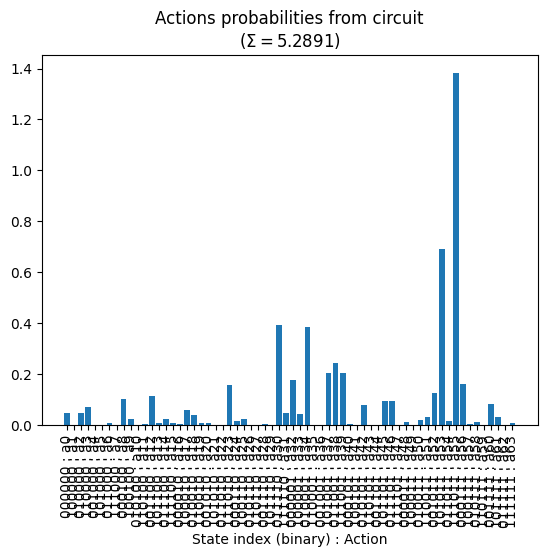

In [35]:
### Probabilities derived from measuring the returns qubits in the circuit.
### NOTE - I've found that the result plotted below will be scaled by a factor of 1/n_actions.

plt.bar(np.arange(n_actions), probs_actions)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Actions probabilities from circuit\n($\\Sigma = {probs_actions.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")

In [36]:
probs_actions.sum()

tensor(5.28910348, requires_grad=True)

In [37]:
probs_actions.sum()**2

tensor(27.97461567, requires_grad=True)

In [38]:
# Re-normalize the action probabilities to ensure they sum to 1.
probs_actions /= probs_actions.sum()
print(f"{probs_actions=}")

probs_actions=tensor([8.51085052e-03, 1.52344702e-05, 8.49771508e-03, 1.35391833e-02,
        1.21107093e-07, 1.01487936e-05, 1.54507983e-03, 1.11387894e-04,
        1.91677377e-02, 4.33613314e-03, 5.22151122e-05, 3.70257669e-04,
        2.13983012e-02, 1.53056461e-03, 4.30096390e-03, 1.18007574e-03,
        9.70786018e-04, 1.11126443e-02, 7.52607973e-03, 1.13540581e-03,
        1.12549660e-03, 7.62164512e-10, 4.00312044e-06, 2.92491924e-02,
        2.80007021e-03, 3.98599914e-03, 1.87169970e-04, 9.32852919e-06,
        9.79021966e-04, 9.51849110e-05, 7.43360238e-02, 8.45549086e-03,
        3.33775071e-02, 7.85940145e-03, 7.26649547e-02, 1.10094521e-05,
        8.20840497e-06, 3.85541820e-02, 4.57584463e-02, 3.86658041e-02,
        6.08395009e-04, 1.16696485e-04, 1.44975465e-02, 3.56812704e-06,
        1.18156035e-04, 1.73855566e-02, 1.77923813e-02, 5.87114104e-07,
        2.17260639e-03, 1.34804249e-04, 3.48247079e-03, 6.04216840e-03,
        2.36108246e-02, 1.30844456e-01, 3.18207186

In [39]:
(returns_probs_matrix @ returns_atoms_values_original).sum() / probs_actions.sum()

tensor(1582.47031063, requires_grad=True)

In [40]:
from collections import namedtuple
ActionRank = namedtuple("ActionRank", ["action", "rank"])

In [41]:
### Rank actions from high-to-low based on their weighted expected return.

action_rank_manual_compute, _ = zip(*sorted(list(enumerate(returns_probs_matrix @ returns_atoms_values_original)), key=lambda tup: tup[1])[::-1]) # List of action indices where location in list indicates action rank in descending order (high -> low).
action_rank_manual_compute = list(ActionRank(action, rank) for rank,action in enumerate(action_rank_manual_compute)) # [(action_index, rank), ...]
action_rank_manual_compute

[ActionRank(action=55, rank=0),
 ActionRank(action=53, rank=1),
 ActionRank(action=30, rank=2),
 ActionRank(action=34, rank=3),
 ActionRank(action=38, rank=4),
 ActionRank(action=39, rank=5),
 ActionRank(action=37, rank=6),
 ActionRank(action=32, rank=7),
 ActionRank(action=56, rank=8),
 ActionRank(action=23, rank=9),
 ActionRank(action=52, rank=10),
 ActionRank(action=12, rank=11),
 ActionRank(action=8, rank=12),
 ActionRank(action=46, rank=13),
 ActionRank(action=45, rank=14),
 ActionRank(action=60, rank=15),
 ActionRank(action=42, rank=16),
 ActionRank(action=3, rank=17),
 ActionRank(action=17, rank=18),
 ActionRank(action=0, rank=19),
 ActionRank(action=2, rank=20),
 ActionRank(action=31, rank=21),
 ActionRank(action=33, rank=22),
 ActionRank(action=18, rank=23),
 ActionRank(action=51, rank=24),
 ActionRank(action=61, rank=25),
 ActionRank(action=9, rank=26),
 ActionRank(action=14, rank=27),
 ActionRank(action=25, rank=28),
 ActionRank(action=50, rank=29),
 ActionRank(action=54, ra

In [42]:
### Rank actions from high-to-low based on their circuit probability.

action_rank_circuit_probs, _ = zip(*sorted(list(enumerate(probs_actions)), key=lambda tup: tup[1])[::-1]) # List of action indices where location in list indicates action rank in descending order (high -> low).
action_rank_circuit_probs = list(ActionRank(action, rank) for rank,action in enumerate(action_rank_circuit_probs)) # [(action_index, rank), ...]
action_rank_circuit_probs

[ActionRank(action=55, rank=0),
 ActionRank(action=53, rank=1),
 ActionRank(action=30, rank=2),
 ActionRank(action=34, rank=3),
 ActionRank(action=38, rank=4),
 ActionRank(action=39, rank=5),
 ActionRank(action=37, rank=6),
 ActionRank(action=32, rank=7),
 ActionRank(action=56, rank=8),
 ActionRank(action=23, rank=9),
 ActionRank(action=52, rank=10),
 ActionRank(action=12, rank=11),
 ActionRank(action=8, rank=12),
 ActionRank(action=46, rank=13),
 ActionRank(action=45, rank=14),
 ActionRank(action=60, rank=15),
 ActionRank(action=42, rank=16),
 ActionRank(action=3, rank=17),
 ActionRank(action=17, rank=18),
 ActionRank(action=0, rank=19),
 ActionRank(action=2, rank=20),
 ActionRank(action=31, rank=21),
 ActionRank(action=33, rank=22),
 ActionRank(action=18, rank=23),
 ActionRank(action=51, rank=24),
 ActionRank(action=61, rank=25),
 ActionRank(action=9, rank=26),
 ActionRank(action=14, rank=27),
 ActionRank(action=25, rank=28),
 ActionRank(action=50, rank=29),
 ActionRank(action=54, ra

In [43]:
### Verify manually computed action rank is the same as the rank estimated by the circuit.

action_rank_manual_compute == action_rank_circuit_probs

True

Text(0.5, 1.0, 'Comparison of action probabilities between circuit and manual computation\n(Action ranking provided above each bar, lower rank number is better)\nRank match = True')

<Figure size 640x480 with 0 Axes>

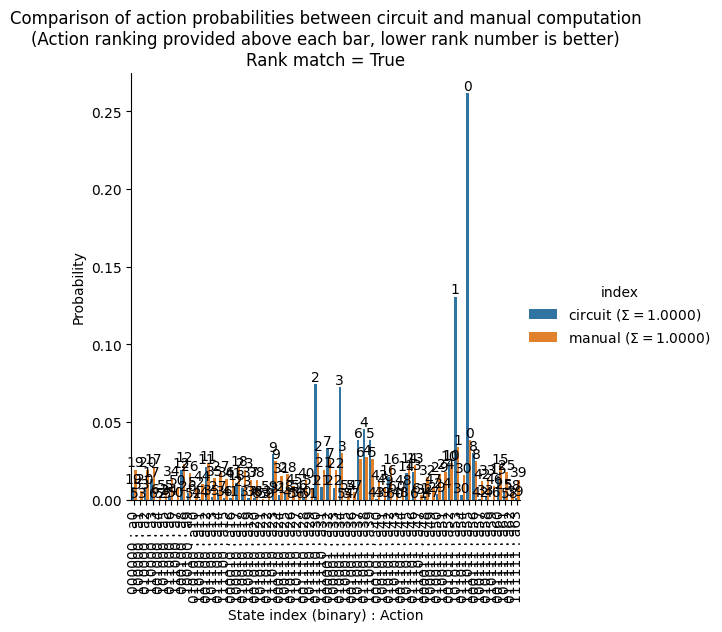

In [44]:
### To make visual comparison easier, plot action probabilities from quantum circuit and manual computation together on same chart.

# Compute manual returns probabilities.
# y = returns_probs_matrix @ returns_atoms_values_original
y = returns_probs_matrix @ returns_atoms_values_original_normalized
y /= y.sum()

# Plot circuit action probabilities and manual computation action probabilities together.
df = pd.DataFrame(np.array([probs_actions, y]), columns=[f"a{i}" for i in range(n_actions)], index=[f"circuit ($\\Sigma = {probs_actions.sum():.4f}$)", f"manual ($\\Sigma = {y.sum():.4f}$)"])
df = df.reset_index()
df = df.melt(id_vars='index')

plt.figure()
g = sns.catplot(data=df, x='variable', y='value', hue='index', kind="bar", legend=True)
ax = g.facet_axis(0, 0)
for idx, (container, actionrank) in enumerate(zip(ax.containers, [action_rank_circuit_probs, action_rank_manual_compute])):
    # labels = [f"{v.get_height():.4f}" for v in container]
    actionrank = sorted(actionrank, key=lambda ar: ar.action)
    labels = [f"{actionrank[j].rank}" for j, v in enumerate(container)]
    ax.bar_label(container, labels=labels, label_type='edge')
g.set_xticklabels([f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
g.set_xlabels("State index (binary) : Action")
g.set_ylabels("Probability")
plt.title(f"Comparison of action probabilities between circuit and manual computation\n(Action ranking provided above each bar, lower rank number is better)\nRank match = {action_rank_manual_compute == action_rank_circuit_probs}")

Text(0.5, 0, 'State index (binary) : Return atom')

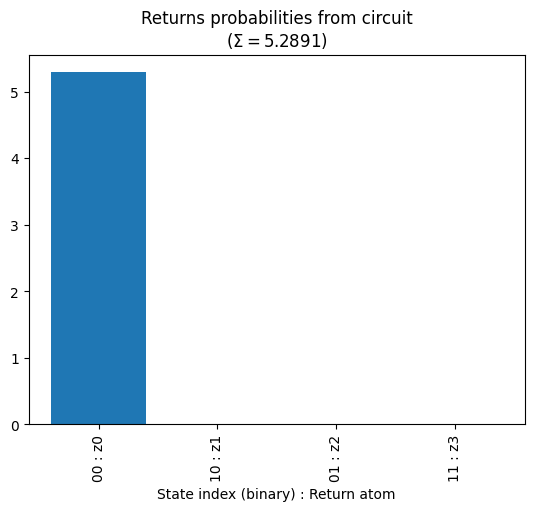

In [45]:
### Probabilities derived from measuring the returns qubits in the circuit.

plt.bar(np.arange(n_returns), probs_returns)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Returns probabilities from circuit\n($\\Sigma = {probs_returns.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")